# Regional Market Price Behaviour Segmentation for Comparative Pattern Analysis
**Units II, III & IV - Partition Clustering, Hierarchical Comparison, PCA Visualisation**

Unit of analysis: **markets (mandis)**, each summarised by a feature vector built from its price history.
`RANDOM_STATE = 42` everywhere. The data file is set in `config.yaml`; if it is absent a clearly labelled **synthetic** dataset
is generated so this notebook still runs - synthetic results are for demonstration only.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score
from src import preprocess as pp, features as ft, clustering as cl, validation as va, visualise as vz, pipeline as pl

cfg = pp.load_config("config.yaml")
OUT, FIG = Path(cfg["output_dir"]), Path(cfg["output_dir"]) / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
log = pp.PreprocessingLog()

## Objective 1 - Data preparation
Load, filter to one commodity, review variables, repair impossible values, handle missing data.

In [2]:
c = pl.stage_clean(cfg, log)
df = c["df"]
print("\nShape:", df.shape, "| date range:", df.Arrival_Date.min().date(), "->", df.Arrival_Date.max().date())
display(df.groupby("State")["market_id"].nunique().rename("markets per state").to_frame().T)

[Loading] Loaded data/agmarknet_wheat.csv.gz; renamed columns {'State/UT': 'State', 'District': 'District', 'Market': 'Market', 'Commodity Group': 'Commodity_Group', 'Commodity': 'Commodity', 'Variety': 'Variety', 'Grade': 'Grade', 'Min Price': 'Min_Price', 'Max Price': 'Max_Price', 'Modal Price': 'Modal_Price', 'Price Unit': 'Price_Unit', 'Arrival Quantity': 'Arrivals', 'Arrival Unit': 'Arrival_Unit', 'Arrival Date': 'Arrival_Date'}
[Loading] Raw shape (269406, 14); dtypes: State=str, District=str, Market=str, Commodity_Group=str, Commodity=str, Variety=str, Grade=str, Min_Price=str, Max_Price=str, Modal_Price=str, Price_Unit=str, Arrivals=str, Arrival_Unit=str, Arrival_Date=str
[Filtering] Filtered to commodity 'Wheat': 269,406 rows
[Missing values] Percent missing per column: State=0.0%, District=0.0%, Market=0.0%, Commodity_Group=0.0%, Commodity=0.0%, Variety=0.0%, Grade=0.0%, Min_Price=0.0%, Max_Price=0.0%, Modal_Price=0.0%, Price_Unit=0.0%, Arrivals=0.0%, Arrival_Unit=0.0%, Arriv

[Impossible values] Min_Price: 0 zero/negative values set to NaN
[Impossible values] Max_Price: 0 zero/negative values set to NaN
[Impossible values] Modal_Price: 0 zero/negative values set to NaN
[Impossible values] 0 rows with Min_Price > Max_Price: values swapped
[Impossible values] 9 Modal_Price values outside [median/5, median x 5] (median 2,468) treated as entry errors -> NaN
[Impossible values] 12 Max_Price values > 5x Modal and 143 Min_Price values < Modal/5 treated as entry errors -> NaN (row kept; Modal is the primary signal)
[Missing values] 9 missing Modal_Price rows filled with (Min+Max)/2
[Missing values] Dropped 0 rows whose Modal_Price is still missing
[Impossible values] 2 rows with Modal outside [Min, Max]: clipped into range
[Cleaning] Dropped 0 exact duplicate rows; 269,406 rows remain



Shape: (269406, 16) | date range: 2025-11-07 -> 2026-11-03


State,Bihar,Chattisgarh,Gujarat,Haryana,Himachal Pradesh,Karnataka,Madhya Pradesh,Maharashtra,NCT of Delhi,Nagaland,Punjab,Rajasthan,Telangana,Uttar Pradesh,Uttarakhand,West Bengal
markets per state,10,64,116,84,1,68,264,225,2,1,131,134,4,249,9,17


,column,n_unique,pct_missing,decision,justification
0,State,16,0.0,Keep (label only),Used post hoc to interpret clusters; NOT a clu...
1,District,335,0.0,Drop,Nested inside Market/State; near-unique ID add...
2,Market,1366,0.0,Keep (unit ID),"Unit of analysis; an identifier, never a feature"
3,Commodity_Group,1,0.0,Drop,Constant after commodity filter - carries no i...
4,Commodity,1,0.0,Drop,Constant after commodity filter - carries no i...
5,Variety,88,0.0,Keep (aggregated),Median across varieties/grades per market-week...
6,Grade,6,0.0,Keep (aggregated),Median across varieties/grades per market-week...
7,Min_Price,3053,0.0,Keep,Used for intraday spread (Max-Min)/Modal and d...
8,Max_Price,3817,0.0,Keep,Used for intraday spread (Max-Min)/Modal and d...
9,Modal_Price,19859,0.0,Keep,Primary price signal (most frequent traded price)


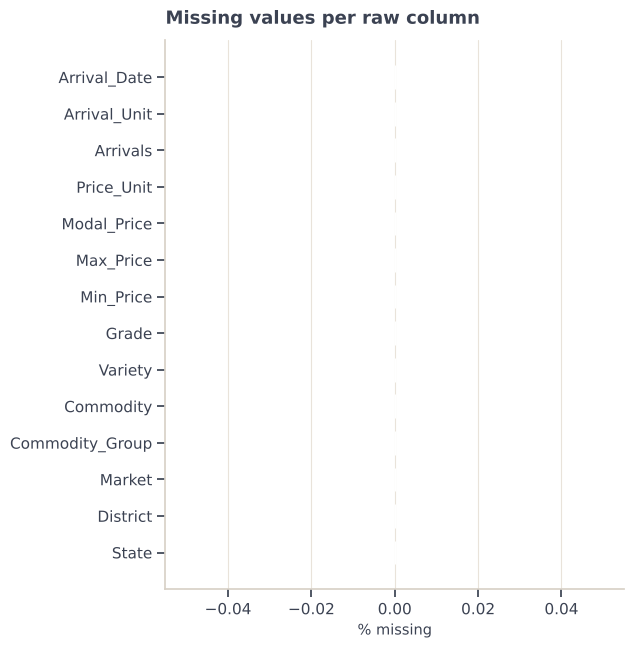

In [3]:
display(c["relevance"])                       # variable relevance review (keep / drop + justification)
vz.plot_missingness(c["relevance"], FIG / "06_missingness.png"); plt.show()

### Feature engineering, correlation pruning, standardisation
Prices are aggregated to **market-week medians** (this collapses variety/grade mixing). Markets with <60% day coverage are dropped, short gaps
are time-interpolated, outliers are winsorised (clipped, never silently deleted). `State` is a post-hoc label only (not a feature).

[Market filtering] 426 of 1379 markets kept (coverage >= 60% of calendar days and >= 100 rows); dropped: Bihar | Aurangabad APMC, Bihar | Bahadurganj APMC, Bihar | Barbigha APMC, Bihar | Bihariganj APMC, Bihar | Jainagar APMC, Bihar | Kishanganj APMC, Bihar | Lakhisarai APMC, Bihar | Muzaffarpur APMC, Bihar | Saidpurhat APMC, Bihar | Shekhpura APMC, Chattisgarh | Ambikapur APMC, Chattisgarh | Baikunthpur APMC, Chattisgarh | Baramkela APMC, Chattisgarh | Bariya APMC, Chattisgarh | Bemetara APMC, Chattisgarh | Bemetara(Navagarh) APMC, Chattisgarh | Bemetara(Thankhamaria) APMC, Chattisgarh | Berla APMC, Chattisgarh | Bhatapara APMC, Chattisgarh | Bilaspur APMC, Chattisgarh | Bilha APMC, Chattisgarh | Biranpur kalan (Sahaspur Lohra) APMC, Chattisgarh | Dadhi APMC, Chattisgarh | Dhamtari APMC, Chattisgarh | Dondi APMC, Chattisgarh | Dondilohara APMC, Chattisgarh | Dongargarh APMC, Chattisgarh | Durg APMC, Chattisgarh | Gandai APMC, Chattisgarh | Jagdalpur APMC, Chattisgarh | Jashpur APMC, C

[Feature engineering] 15 candidate features (State and coverage excluded from clustering): mean_modal = Mean weekly modal price (Rs/quintal); median_modal = Median weekly modal price; min_price = Lowest weekly modal price; max_price = Highest weekly modal price; std_modal = Std of weekly modal price; cv = Coefficient of variation = std / mean; range_ratio = (max - min) / median of weekly modal price; mean_spread = Mean daily (Max-Min)/Modal intraday spread; skewness = Skewness of weekly price distribution; kurtosis = Excess kurtosis of weekly price distribution; seasonal_amp = (max - min) of calendar-month mean price / overall mean; trend_slope = Linear trend per year / mean price (relative drift); volatility = Mean absolute week-on-week % return; share_above_regional = Share of weeks priced above the cross-market weekly median; avg_arrivals = Mean reported daily arrivals (supply volume)
[Encoding] State is kept only as a post-hoc interpretation label; no one-hot encoding was needed be

,n_obs,coverage,keep,reason
market_id,,,,
Bihar | Aurangabad APMC,6,0.016575,False,coverage < 60%
Bihar | Bahadurganj APMC,13,0.035912,False,coverage < 60%
Bihar | Barbigha APMC,142,0.392265,False,coverage < 60%
Bihar | Bihariganj APMC,5,0.013812,False,coverage < 60%
Bihar | Jainagar APMC,8,0.022099,False,coverage < 60%
Bihar | Kishanganj APMC,22,0.060773,False,coverage < 60%
Bihar | Lakhisarai APMC,5,0.013812,False,coverage < 60%
Bihar | Muzaffarpur APMC,37,0.102210,False,coverage < 60%
Bihar | Saidpurhat APMC,4,0.011050,False,coverage < 60%


,count,mean,std,min,25%,50%,75%,max
mean_modal,426.0,2500.838,126.978,2312.186,2444.703,2482.453,2526.574,4053.846
median_modal,426.0,2497.385,127.265,2300.000,2438.220,2477.750,2525.875,3950.000
min_price,426.0,2255.729,143.659,1875.000,2181.250,2240.000,2300.699,3750.000
max_price,426.0,2837.246,243.603,2400.000,2625.000,2826.250,2998.750,4750.000
std_modal,426.0,134.349,52.125,0.000,95.974,138.320,168.357,333.146
cv,426.0,0.054,0.020,0.000,0.039,0.055,0.067,0.120
range_ratio,426.0,0.232,0.104,0.000,0.145,0.241,0.309,0.663
mean_spread,426.0,0.081,0.089,0.000,0.020,0.055,0.113,0.623
skewness,423.0,0.293,0.557,-1.421,-0.045,0.268,0.600,3.038
kurtosis,423.0,0.116,1.221,-1.877,-0.736,-0.121,0.716,12.396


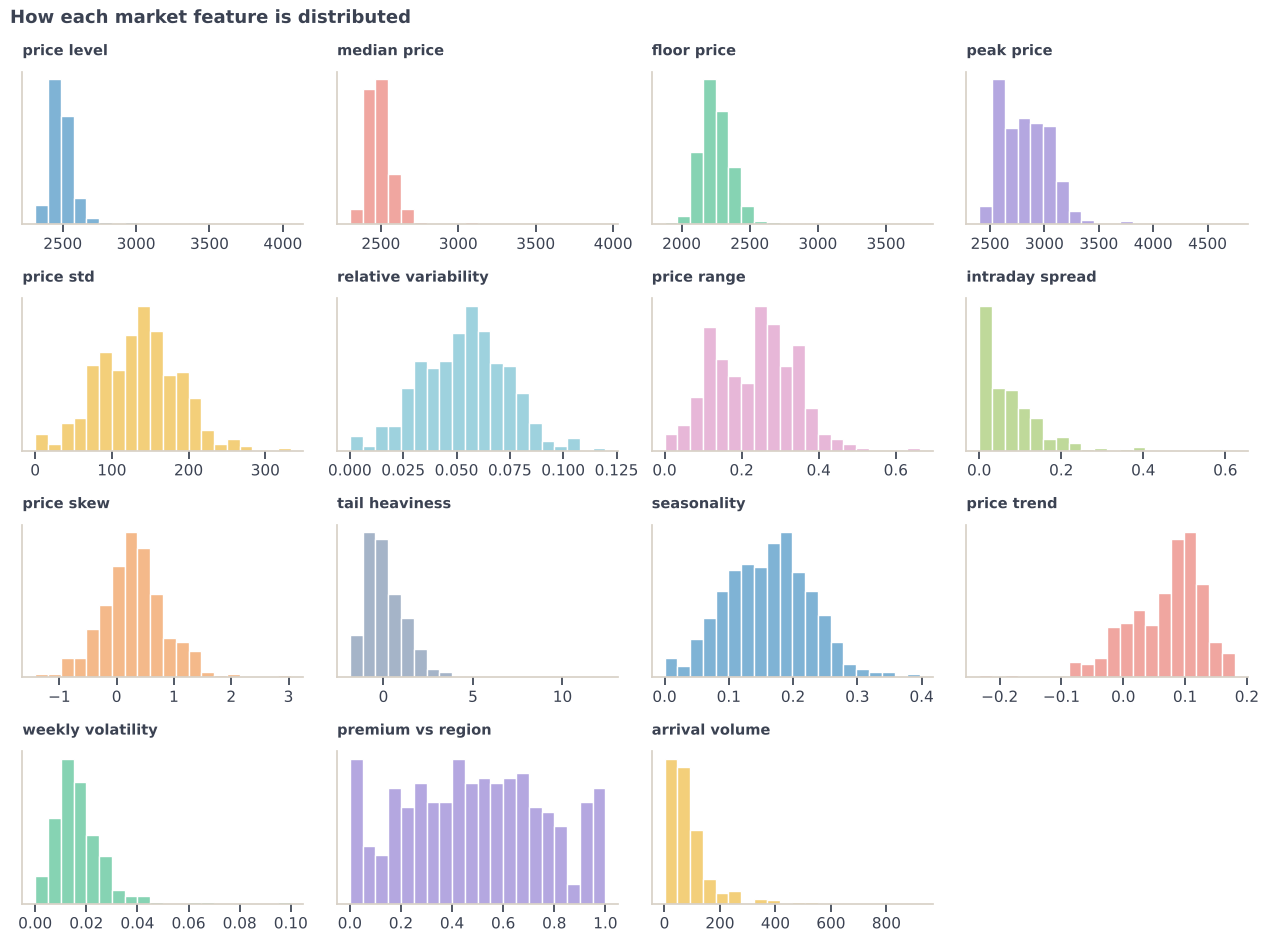

,dropped,kept_partner,abs_r
0,std_modal,cv,0.991
1,mean_modal,median_modal,0.977
2,cv,seasonal_amp,0.948
3,range_ratio,seasonal_amp,0.912


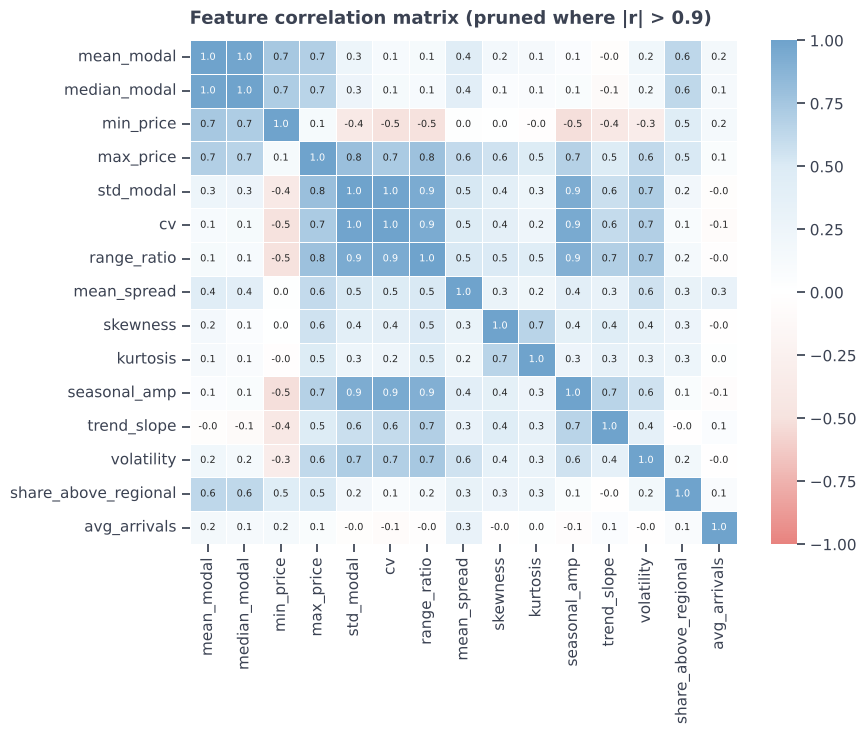

In [4]:
f = pl.stage_features(df, cfg, log)
X = f["X"]
print("\n", len(f["dropped"]), "markets dropped (first 15 shown):"); display(f["dropped"].head(15))
display(f["feat"].describe().T.round(3))
vz.plot_feature_distributions(f["feat"], f["initial"], FIG / "07_feature_distributions.png"); plt.show()
display(f["corr_dropped"])
vz.plot_correlation(f["corr"].loc[f["initial"], f["initial"]], cfg["preprocessing"]["corr_threshold"], FIG / "08_correlation.png"); plt.show()

## Objective 2 - Clustering workflow
K-Means (Euclidean) and K-Medians (Manhattan: L1 assignment + median update) for K = 2..10; WCSS/L1 cost, Silhouette, Davies-Bouldin with matching metric.

In [5]:
g = pl.stage_grid(X, cfg)
grid = g["grid"]
display(grid.round(4))

,distance,k,cost,silhouette,davies_bouldin,pca2_silhouette,min_cluster_size,min_cluster_frac
0,euclidean,2,3442.7112,0.2741,1.4052,0.4459,208,0.4883
1,euclidean,3,2953.8894,0.2825,1.1771,0.4595,5,0.0117
2,euclidean,4,2538.2820,0.2194,1.1919,0.4176,3,0.0070
3,euclidean,5,2320.0330,0.2292,1.3086,0.3423,3,0.0070
4,euclidean,6,2121.5850,0.1866,1.4026,0.3152,3,0.0070
5,euclidean,7,2003.8440,0.1794,1.3817,0.2980,3,0.0070
6,euclidean,8,1884.4067,0.1808,1.3645,0.2723,1,0.0023
7,euclidean,9,1787.1011,0.1823,1.3622,0.2760,2,0.0047
8,euclidean,10,1701.9017,0.1776,1.1912,0.2349,1,0.0023
9,manhattan,2,2610.6337,0.3167,1.2550,0.4403,190,0.4460


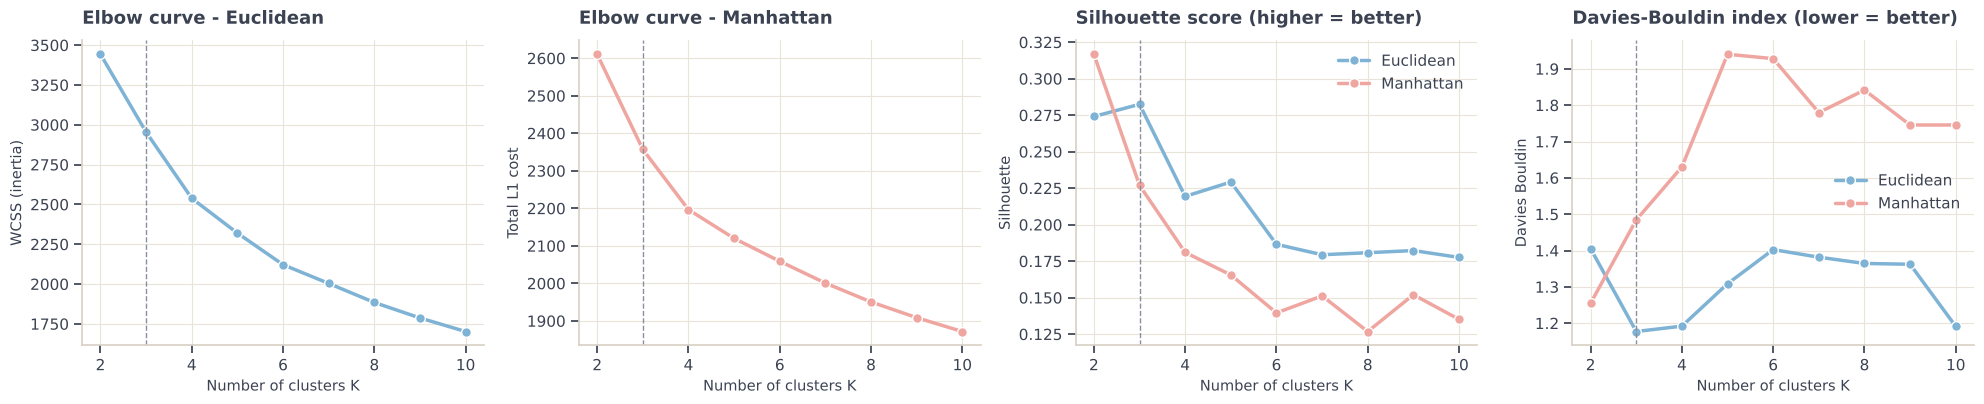

In [6]:
ranked, best, runner = va.select_configuration(grid, cfg)
dist, k = best["distance"], int(best["k"])
vz.plot_metric_curves(grid, k, FIG / "12_metric_curves_all.png"); plt.show()

### PCA - variance explained and loadings

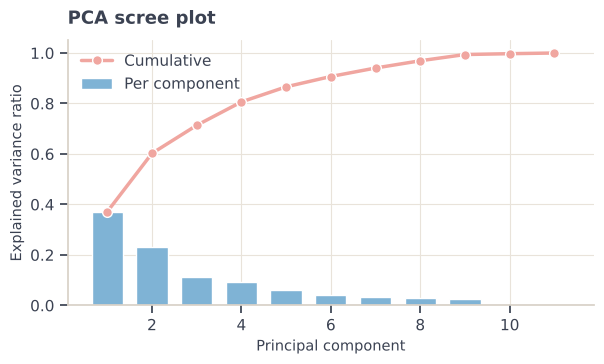

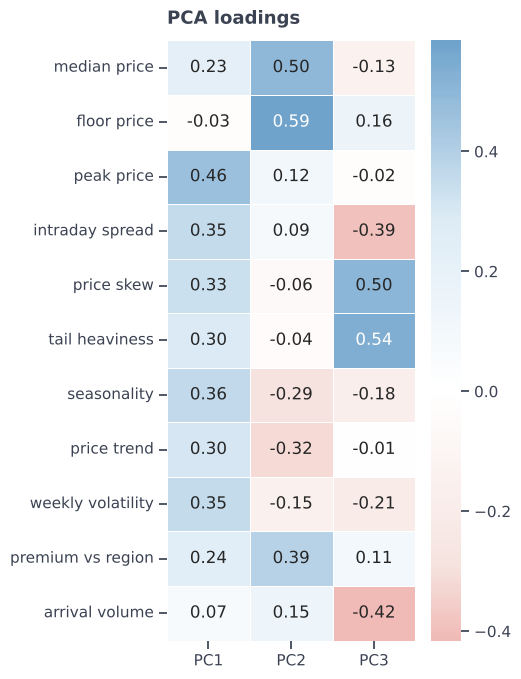

In [7]:
pca, P = g["pca"], g["P"]
vz.plot_scree(pca.explained_variance_ratio_, FIG / "14_pca_scree.png"); plt.show()
_, loadings = vz.plot_loadings(pca, list(X.columns), path=FIG / "15_pca_loadings.png"); plt.show()

### Decision rule and final configuration
Eligible: K >= 3 and smallest cluster >= 5% of markets. Score = mean of min-max-normalised **Silhouette, -Davies-Bouldin, PCA-2D silhouette**.
Euclidean is preferred unless Manhattan wins by more than the tie tolerance. Elbow K is flagged for reference. Runner-up is the next-best different configuration.

,distance,k,cost,silhouette,davies_bouldin,pca2_silhouette,min_cluster_size,min_cluster_frac,is_elbow,composite
0,manhattan,3,2356.9623,0.2269,1.4844,0.3531,129,0.3028,False,1.0000
1,manhattan,4,2196.5083,0.1810,1.6300,0.3379,83,0.1948,True,0.7188
2,manhattan,7,2000.7387,0.1512,1.7796,0.2056,23,0.0540,False,0.3199
3,manhattan,5,2119.9391,0.1656,1.9402,0.2532,65,0.1526,False,0.3188
4,manhattan,6,2058.9279,0.1396,1.9281,0.2248,50,0.1174,False,0.2002
5,manhattan,8,1950.5173,0.1268,1.8417,0.1213,23,0.0540,False,0.0720


CHOSEN: manhattan K=3   |   RUNNER-UP: manhattan K=4


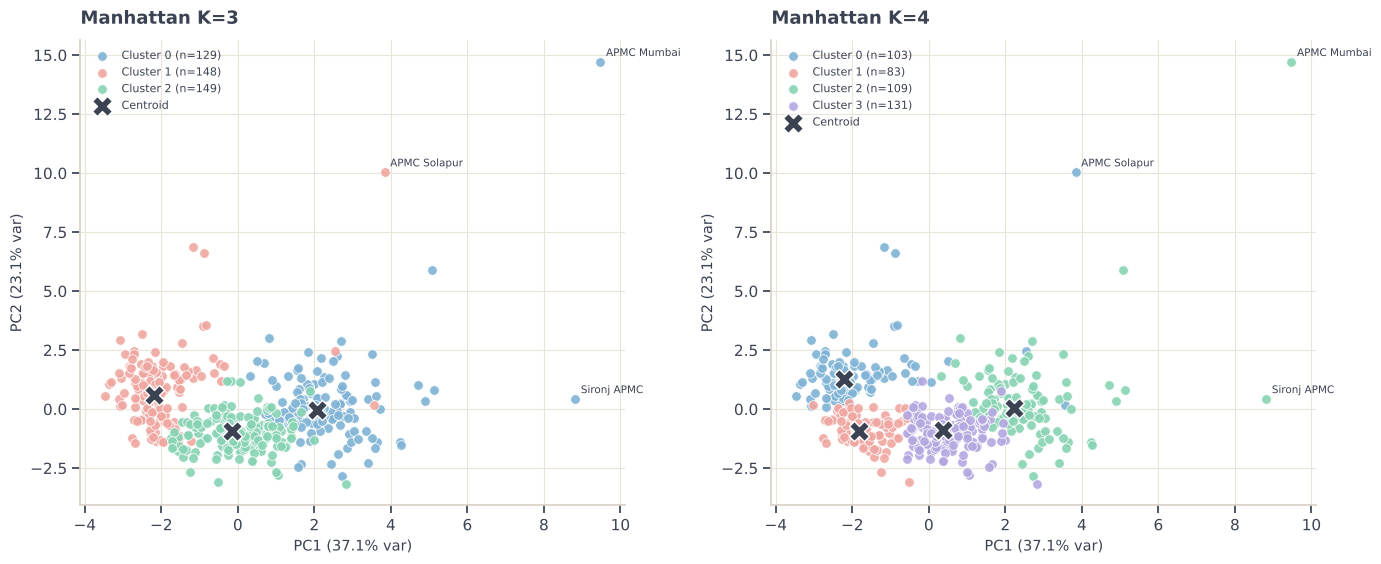

In [8]:
display(ranked.head(8).round(4))
print(f"CHOSEN: {dist} K={k}   |   RUNNER-UP: {runner['distance']} K={int(runner['k'])}")
fit = g["fits"][(dist, k)]
panels = []
for d in ["euclidean", "manhattan"]:
    for _, r in ranked[ranked.distance == d].head(2).iterrows():
        m = g["fits"][(d, int(r.k))]
        panels.append((f"{d.title()} K={int(r.k)}", m.labels, pca.transform(m.centers)[:, :2]))
vz.plot_pca_scatter(P, X.index, pca.explained_variance_ratio_, panels, path=FIG / "16_pca_clusters.png"); plt.show()

### Hierarchical comparison (Unit III) - Ward linkage vs the chosen partition

Cophenetic correlation (Ward): 0.389 | ARI Ward vs manhattan K=3: 0.371


Ward,0,1,2
Partition,,,
0,3,2,124
1,132,3,13
2,118,0,31


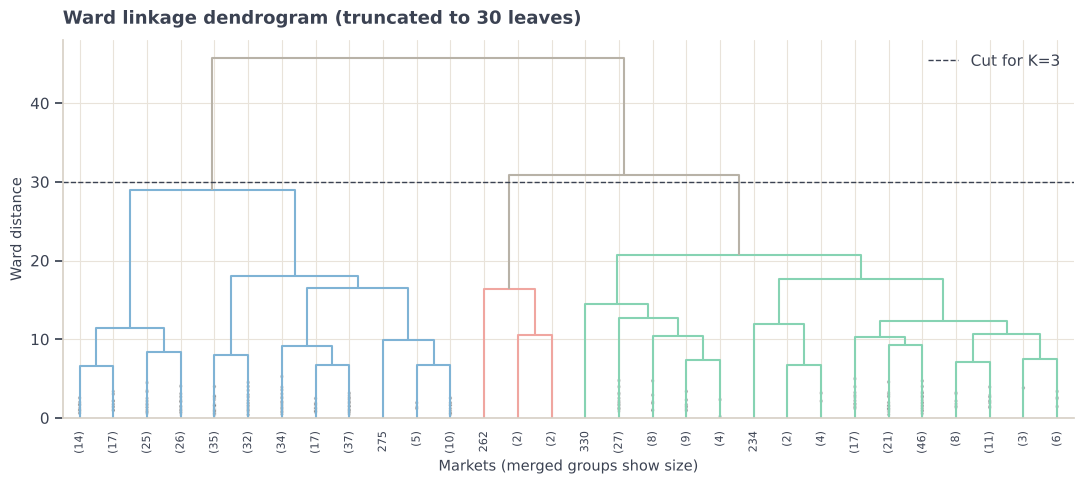

In [9]:
Z, hl, coph = cl.ward_hierarchy(X.values, k)
ari_h = adjusted_rand_score(fit.labels, hl)
print(f"Cophenetic correlation (Ward): {coph:.3f} | ARI Ward vs {dist} K={k}: {ari_h:.3f}")
display(pd.crosstab(pd.Series(fit.labels, name="Partition"), pd.Series(hl, name="Ward")))
vz.plot_dendrogram(Z, k, FIG / "17_dendrogram.png"); plt.show()

## Objective 3 - Interpretation and responsible reporting
Profiles, feature contributions, stability, limitations. **Cluster names are provisional, auto-generated descriptions, not real-world categories.**

,name,n_markets
0,"high peak price, high premium vs region (provi...",129
1,"low seasonality, low price trend (provisional)",148
2,"low premium vs region, low floor price (provis...",149


Mean of original-scale features per cluster:


,0,1,2
median_modal,2565.275,2482.692,2453.203
min_price,2255.171,2331.008,2181.438
max_price,3097.982,2625.383,2821.950
mean_spread,0.143,0.027,0.080
skewness,0.746,-0.088,0.278
kurtosis,1.058,-0.449,-0.142
seasonal_amp,0.211,0.092,0.187
trend_slope,0.102,0.009,0.100
volatility,0.024,0.009,0.017
share_above_regional,0.731,0.451,0.321


Median:


,0,1,2
median_modal,2546.000,2462.785,2460.000
min_price,2225.000,2309.402,2195.000
max_price,3080.000,2600.000,2828.000
mean_spread,0.124,0.015,0.062
skewness,0.724,-0.113,0.267
kurtosis,1.024,-0.737,-0.201
seasonal_amp,0.204,0.098,0.186
trend_slope,0.108,0.014,0.100
volatility,0.023,0.009,0.016
share_above_regional,0.736,0.459,0.321


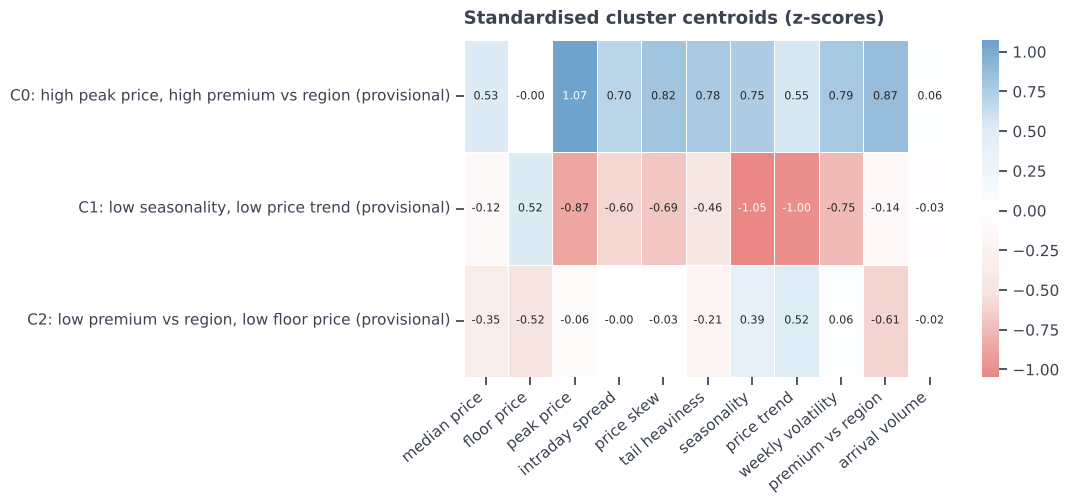

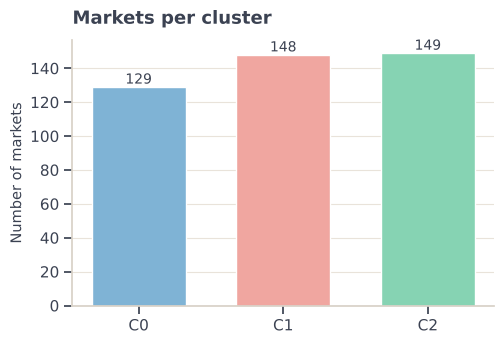

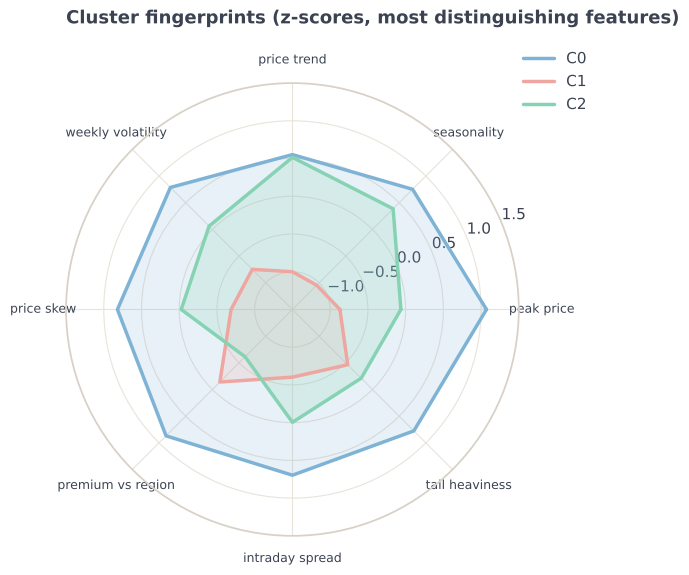

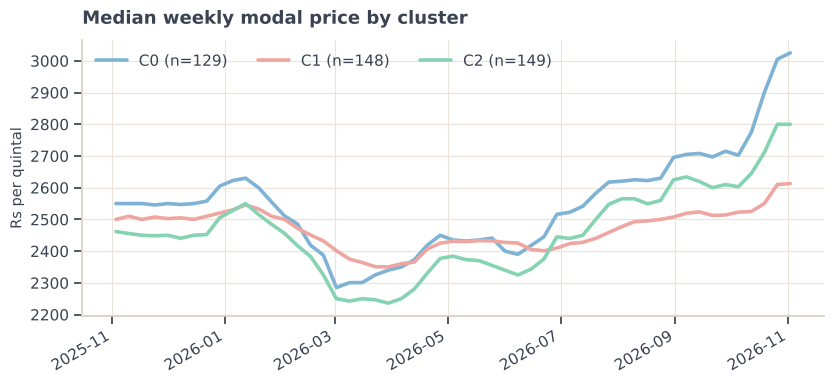

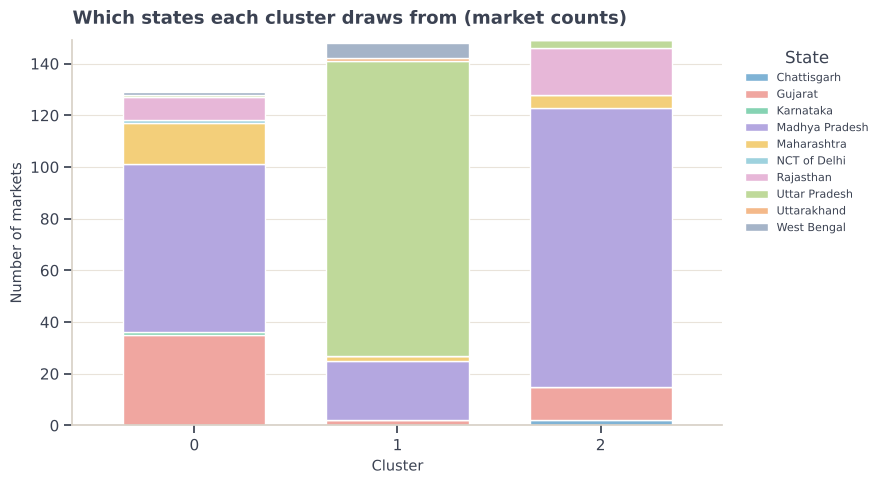

In [10]:
it = pl.stage_interpret(X, f, fit)
display(pd.DataFrame({"name": it["names"], "n_markets": it["sizes"]}))
print("Mean of original-scale features per cluster:"); display(it["mean"].round(3).T)
print("Median:"); display(it["median"].round(3).T)
vz.plot_centroid_heatmap(it["centroids_z"], it["names"], FIG / "21_centroid_heatmap.png"); plt.show()
vz.plot_cluster_sizes(it["sizes"], FIG / "19_cluster_sizes.png"); plt.show()
vz.plot_radar(it["centroids_z"], FIG / "20_cluster_radar.png"); plt.show()
vz.plot_trends(f["weekly"], it["labels"], X.index, FIG / "22_price_trends.png"); plt.show()
vz.plot_state_composition(it["state_ct"], FIG / "23_state_composition.png"); plt.show()

Feature contributions (ANOVA F, eta-squared effect size, centroid range) - plus PCA loadings above


,anova_F,p_value,eta_squared,centroid_range
max_price,334.3189,0.0000,0.6125,1.9423
seasonal_amp,321.7698,0.0000,0.6034,1.7975
trend_slope,241.1816,0.0000,0.5328,1.5523
volatility,131.4511,0.0000,0.3833,1.5350
skewness,122.8977,0.0000,0.3675,1.5064
share_above_regional,122.3345,0.0000,0.3665,1.4810
mean_spread,79.5090,0.0000,0.2732,1.2995
kurtosis,79.2234,0.0000,0.2725,1.2392
min_price,49.4124,0.0000,0.1894,1.0424
median_modal,32.5214,0.0000,0.1333,0.8817


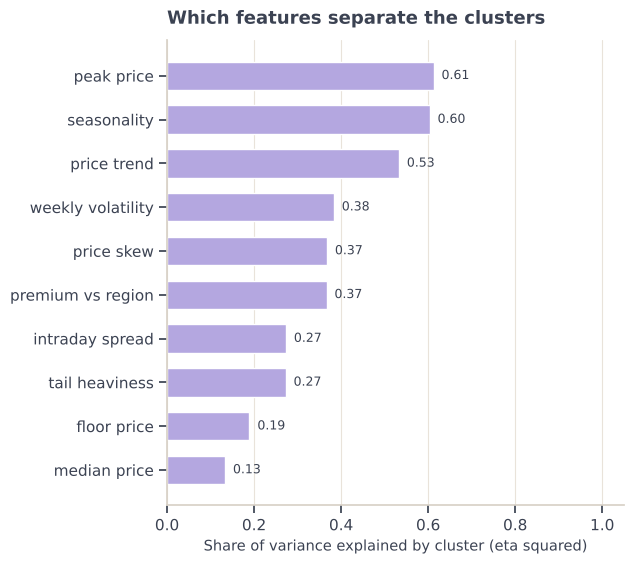

In [11]:
print("Feature contributions (ANOVA F, eta-squared effect size, centroid range) - plus PCA loadings above")
display(it["contrib"].round(4))
vz.plot_contrib(it["contrib"], FIG / "24_feature_drivers.png"); plt.show()

### Stability analysis
(a) 20 random single-start seeds, (b) 50 bootstrap 80% subsamples, (c) Euclidean vs Manhattan labels, (d) sensitivity: no winsorising / without shape features / without dynamics features.
Verdict from the mean ARI: >= 0.8 stable, 0.5-0.8 moderately stable, < 0.5 unstable.

,mean ARI
Random seeds,0.763
Bootstrap 80%,0.774
Manhattan vs Euclidean,0.404
Sensitivity scenarios,0.686


,scenario,n_features,ari_vs_final
0,No winsorising,12,0.759
1,Without shape group,9,0.609
2,Without dynamics group,8,0.690


Overall mean ARI = 0.657  ->  MODERATELY STABLE


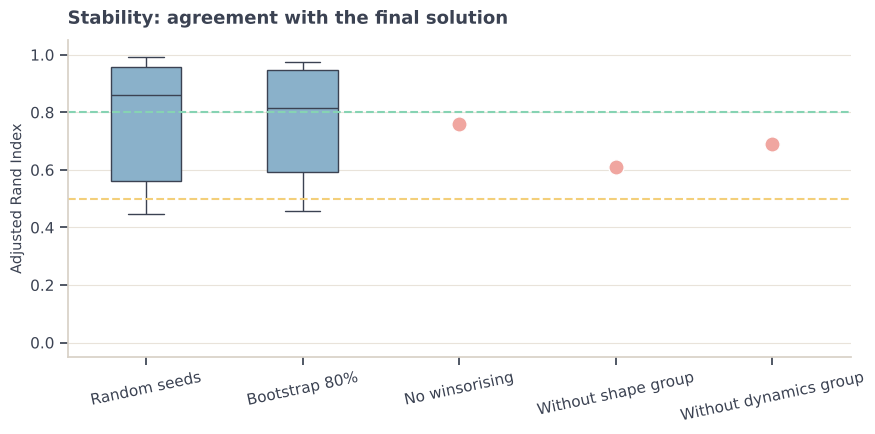

In [12]:
st = pl.stage_stability(df, cfg, f, dist, k, fit.labels)
display(pd.Series(st["components"], name="mean ARI").round(3).to_frame())
display(st["sens"].round(3))
print(f"Overall mean ARI = {st['overall']:.3f}  ->  {st['verdict'].upper()}")
vz.plot_stability(st["seeds"], st["boot"], st["sens"], FIG / "26_stability.png"); plt.show()

### Farmer-facing layer (SIH26132) - where to sell after transport
Per-market recent price (4-week median), momentum and volatility are combined with distance to a farmer location.
**Net price = price x (1 - fee) - transport rate x road km.** Transport rate and fee are configurable *assumptions*. Coordinates are *approximate* place centroids matched from State/District/Market names (or your own `data/mandi_coordinates.csv`).

In [13]:
from src import advisor as adv
coords = adv.market_coordinates(X.index, cfg, c["synthetic"], df)
if coords is None:
    print("No data/mandi_coordinates.csv - distance-based ranking skipped (see README). Showing price behaviour by cluster instead.")
    snap = adv.build_snapshot(f["weekly"], f["feat"], it["labels"], it["names"], X.index)
    snap.to_csv(OUT / "market_snapshot.csv")
    display(snap.groupby("cluster_name").agg(markets=("State", "size"), median_recent_price=("recent_price", "median"),
            avg_momentum_pct=("momentum_pct", "mean"), avg_volatility=("volatility", "mean")).round(3))
else:
    snap = adv.build_snapshot(f["weekly"], f["feat"], it["labels"], it["names"], X.index).join(coords)
    a = cfg["advisor"]
    print(f"Coordinates for {int(snap['lat'].notna().sum())} of {len(snap)} markets:", snap["coord_source"].value_counts().to_dict())
    ranking, csum = adv.rank_markets(snap, a["farmer_lat"], a["farmer_lon"], a["quantity_quintal"],
                                     a["transport_rate_per_quintal_km"], a["road_factor"], a["market_fee_pct"], a["max_km"])
    snap.to_csv(OUT / "market_snapshot.csv"); ranking.to_csv(OUT / "advisor_demo_ranking.csv"); csum.to_csv(OUT / "advisor_demo_clusters.csv", index=False)
    display(csum.round(2))
    display(ranking[["State", "cluster", "recent_price", "road_km", "net_price_per_q", "rank_net", "rank_listed"]].head(8).round(1))

Coordinates for 404 of 426 markets: {'market-name': 303, 'district-name': 101}


,cluster,cluster_name,markets_in_reach,median_net_price,best_net_price,avg_volatility,avg_momentum_pct,best_market,enough_markets
0,0,"high peak price, high premium vs region (provi...",79,2822.61,4294.84,0.02,8.07,Maharashtra | APMC Mumbai,True
1,2,"low premium vs region, low floor price (provis...",32,2669.45,2891.25,0.02,5.37,Maharashtra | APMC Rahuri,True
2,1,"low seasonality, low price trend (provisional)",2,2980.10,3559.33,0.01,0.31,Maharashtra | APMC Solapur,False


,State,cluster,recent_price,road_km,net_price_per_q,rank_net,rank_listed
Maharashtra | APMC Mumbai,Maharashtra,0,4375.0,182.0,4294.8,1,1
Maharashtra | APMC Kalyan,Maharashtra,0,3750.0,140.7,3684.4,2,2
Maharashtra | APMC Solapur,Maharashtra,1,3685.0,444.1,3559.3,3,3
Maharashtra | APMC Akola,Maharashtra,0,3253.8,446.8,3131.8,4,4
Maharashtra | APMC Malegaon,Maharashtra,0,3118.8,128.7,3061.8,5,6
Maharashtra | APMC Kopargaon,Maharashtra,0,3091.0,94.7,3041.1,6,10
Gujarat | Dahod APMC,Gujarat,0,3141.2,414.7,3026.9,7,5
Maharashtra | Lasalgaon(Niphad),Maharashtra,0,3033.0,64.6,2989.8,8,22


### Limitations and possible bias
- **Reporting gaps / uneven coverage:** thin reporters are dropped or interpolated; clusters describe well-reporting mandis and may under-represent remote ones.
- **Variety and grade mixing, arrival effects:** medians hide quality and supply differences that can look like price behaviour.
- **Short window:** about 12 months of one commodity (wheat), so seasonality, trend and harvest-season arrival surges cannot be separated from one-off events.
- **Urban vs remote reporting bias:** better-connected mandis report more consistently.
- **K-Means assumptions:** spherical, similar-variance clusters; sensitive to scaling and outliers (hence standardising and winsorising).
- **PCA / metrics:** PCA 2-D plots lose variance; silhouette and Davies-Bouldin are heuristics and the two distances' scores are not strictly comparable.

### Responsible-use statement
These clusters are **exploratory, data-driven groupings** for one commodity and one time window. They are **not permanent market categories** and must not be used for
pricing decisions, policy targeting, or labelling regions without domain validation.

In [14]:
import json
assign = pd.DataFrame({"market_id": X.index, "State": it["states"].values, "cluster": it["labels"],
                       "cluster_name": [it["names"][x] for x in it["labels"]], "ward_cluster": hl,
                       "PC1": P[:, 0], "PC2": P[:, 1]}).join(f["imputed"], on="market_id")
for name, tbl in {"metrics_grid": grid, "selection_ranking": ranked, "cluster_assignments": assign,
                  "feature_contributions": it["contrib"]}.items():
    tbl.to_csv(OUT / f"{name}.csv", index=(name == "feature_contributions"))
log.add("Model selection", f"Chosen: {dist} K={k}; runner-up {runner['distance']} K={int(runner['k'])}")
log.save(OUT / "preprocessing_log.md")

print("=" * 70, "\nRESULTS SUMMARY", "\n" + "=" * 70)
print("Data           :", "SYNTHETIC (demonstration only)" if c["synthetic"] else "real Agmarknet data")
print(f"Chosen config  : {dist} K={k}  (runner-up: {runner['distance']} K={int(runner['k'])})")
print(f"Metrics        : silhouette={best['silhouette']:.3f}, Davies-Bouldin={best['davies_bouldin']:.3f}, cost={best['cost']:.1f}")
print(f"Stability      : {st['verdict']} (mean ARI {st['overall']:.3f})")
print("Top 3 features :", ", ".join(it["contrib"].index[:3]))
print("Key limitations:"); [print("  -", s) for s in pl.LIMITATIONS[:3]]

[Model selection] Chosen: manhattan K=3; runner-up manhattan K=4
RESULTS SUMMARY 
Data           : real Agmarknet data
Chosen config  : manhattan K=3  (runner-up: manhattan K=4)
Metrics        : silhouette=0.227, Davies-Bouldin=1.484, cost=2357.0
Stability      : moderately stable (mean ARI 0.657)
Top 3 features : max_price, seasonal_amp, trend_slope
Key limitations:
  - Reporting gaps and uneven coverage: markets that report rarely are dropped or interpolated, so the clusters describe well-reporting mandis and may miss remote or low-volume ones.
  - Variety/grade mixing and arrival-quantity effects: prices are medians across varieties and grades, so quality or supply differences can masquerade as 'price behaviour'.
  - Method assumptions: K-Means favours compact, similar-sized spherical groups and is sensitive to scaling and outliers; PCA keeps only part of the variance; silhouette/Davies-Bouldin are heuristics, not truth.


[None, None, None]

In [15]:
print("Folder tree:")
for p in sorted(Path(".").rglob("*")):
    if p.is_file() and not any(x in p.parts for x in (".ipynb_checkpoints", "__pycache__", ".venv")): print("  ", p)
print("""
Run it yourself:
  python -m pip install -r requirements.txt
  python -m streamlit run app.py   # upload app (recommended)
  python run_pipeline.py           # same pipeline from the command line
  jupyter nbconvert --execute --to notebook --inplace notebook.ipynb
""")

Folder tree:
   .streamlit/config.toml
   .vscode/settings.json
   README.md
   app.py
   build_notebook.py
   config.yaml
   data/agmarknet_wheat.csv.gz
   docs/SIH26132_Idea_PPT.pptx
   docs/SIH26132_submission.md
   notebook.ipynb
   outputs/advisor_demo_clusters.csv
   outputs/advisor_demo_ranking.csv
   outputs/cluster_assignments.csv
   outputs/cluster_profile_mean.csv
   outputs/cluster_profile_median.csv
   outputs/correlation_pruning.csv
   outputs/dropped_markets.csv
   outputs/feature_contributions.csv
   outputs/figures/01_state_counts.png
   outputs/figures/02_price_hist.png
   outputs/figures/03_reports_per_month.png
   outputs/figures/04_cleaning.png
   outputs/figures/05_coverage.png
   outputs/figures/06_missingness.png
   outputs/figures/07_feature_distributions.png
   outputs/figures/08_correlation.png
   outputs/figures/09_elbow.png
   outputs/figures/10_silhouette.png
   outputs/figures/11_davies_bouldin.png
   outputs/figures/12_metric_curves_all.png
   outputs/fi